In [1]:
"""
Step 2 — EDA (Exploratory Data Analysis)
Nassau Candy Factory Reallocation & Shipping Optimization Recommendation System
 
Reads the cleaned dataset from Phase 1 and writes summary tables that feed
the research paper / executive summary deliverables. No modeling here —
purely descriptive.
    
"""

'\nStep 2 — EDA (Exploratory Data Analysis)\nNassau Candy Factory Reallocation & Shipping Optimization Recommendation System\n\nReads the cleaned dataset from Phase 1 and writes summary tables that feed\nthe research paper / executive summary deliverables. No modeling here —\npurely descriptive.\n\n'

In [20]:
# ============================================
# STEP 2.1: PREPARE DATA FOR EDA
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Consistent chart formatting
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)

# Load your cleaned dataset from Phase 1 (update the filename/path if needed)
df = pd.read_csv("nassau-candy-factory-optimization/data/NASSAU CANDY\Nassau_Candy_Cleaned_Step.csv")

# Verify it loaded correctly
print("Dataset shape:", df.shape)
display(df.head())

# Confirm important columns
print("\nAvailable columns:")
print(df.columns.tolist())

Dataset shape: (10194, 20)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost,Shipping Lead Time Days,Financial Reconciliation Difference
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28,909.0,8.881784e-16
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60,909.0,0.000000e+00
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00,909.0,8.881784e-16
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30,909.0,8.881784e-16
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90,912.0,0.000000e+00



Available columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Shipping Lead Time Days', 'Financial Reconciliation Difference']


In [25]:
# ============================================
# STEP 2.2: SUMMARY STATISTICS
# ============================================

numeric_columns = [
    "Sales",
    "Units",
    "Gross Profit",
    "Cost",
    "Shipping Lead Time Days"
]

summary_statistics = df[numeric_columns].describe().T

summary_statistics["Missing Values"] = (
    df[numeric_columns].isnull().sum()
)

display(summary_statistics)

,count,mean,std,min,25%,50%,75%,max,Missing Values
Sales,10194.0,13.908537,11.341020,1.25,7.2,10.80,18.00,260.0,0
Units,10194.0,3.791838,2.228317,1.00,2.0,3.00,5.00,14.0,0
Gross Profit,10194.0,9.166451,6.643740,0.25,4.9,7.47,12.25,130.0,0
Cost,10194.0,4.742087,5.061647,0.60,2.4,3.60,5.70,130.0,0
Shipping Lead Time Days,10194.0,1320.841868,262.444892,904.00,1271.0,1274.00,1638.00,1642.0,0


In [26]:
# ============================================
# STEP 2.3: ORDERS BY REGION
# ============================================

orders_by_region = (
    df.groupby("Region")
      .agg(
          Order_Lines=("Row ID", "count"),
          Unique_Orders=("Order ID", "nunique"),
          Total_Sales=("Sales", "sum"),
          Total_Units=("Units", "sum"),
          Total_Gross_Profit=("Gross Profit", "sum")
      )
      .sort_values("Order_Lines", ascending=False)
)

display(orders_by_region)

,Order_Lines,Unique_Orders,Total_Sales,Total_Units,Total_Gross_Profit
Region,,,,,
Pacific,3253,2744,46301.53,12466,30485.94
Atlantic,2986,2476,41197.24,11159,26973.70
Interior,2335,1979,32037.60,8820,21282.49
Gulf,1620,1350,22247.26,6209,14700.67


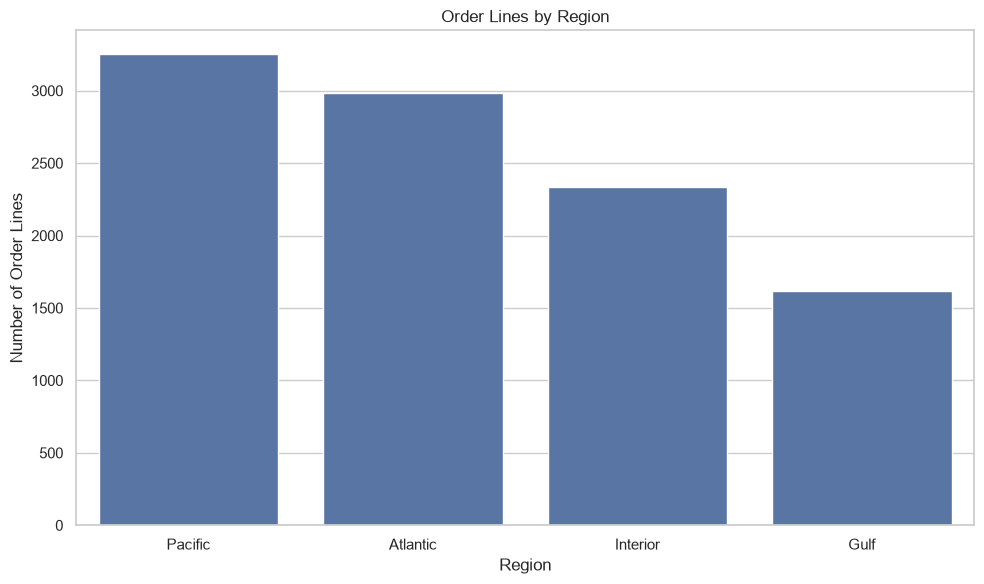

In [27]:
# ============================================
# STEP 2.3A: REGION DISTRIBUTION CHART
# ============================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=orders_by_region.reset_index(),
    x="Region",
    y="Order_Lines"
)

plt.title("Order Lines by Region")
plt.xlabel("Region")
plt.ylabel("Number of Order Lines")

plt.tight_layout()
plt.show()

In [28]:
# ============================================
# STEP 2.4: SHIPPING MODE DISTRIBUTION
# ============================================

shipping_mode_summary = (
    df.groupby("Ship Mode")
      .agg(
          Order_Lines=("Row ID", "count"),
          Unique_Orders=("Order ID", "nunique"),
          Average_Lead_Time=("Shipping Lead Time Days", "mean"),
          Median_Lead_Time=("Shipping Lead Time Days", "median"),
          Average_Sales=("Sales", "mean"),
          Average_Gross_Profit=("Gross Profit", "mean")
      )
      .sort_values("Order_Lines", ascending=False)
)

display(shipping_mode_summary)

,Order_Lines,Unique_Orders,Average_Lead_Time,Median_Lead_Time,Average_Sales,Average_Gross_Profit
Ship Mode,,,,,,
Standard Class,6120,5142,1314.334641,1274.0,13.969011,9.219683
Second Class,1979,1653,1323.845376,1273.0,14.077928,9.250389
First Class,1548,1312,1338.275840,1272.0,13.772216,9.051092
Same Day,547,442,1333.442413,1269.0,13.004881,8.593656


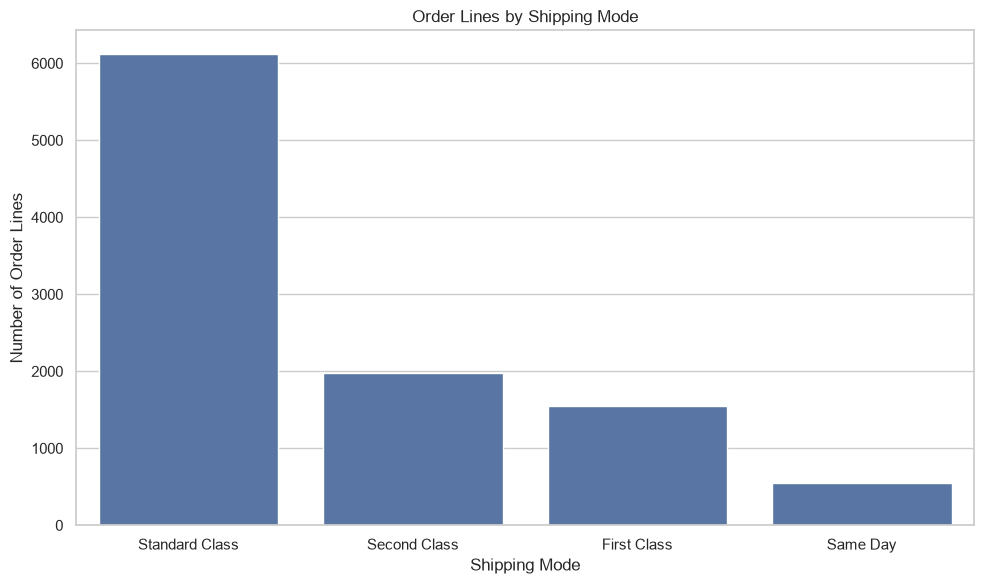

In [29]:
# ============================================
# STEP 2.4A: SHIPPING MODE CHART
# ============================================

shipping_counts = (
    df["Ship Mode"]
      .value_counts()
      .rename_axis("Ship Mode")
      .reset_index(name="Order Lines")
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=shipping_counts,
    x="Ship Mode",
    y="Order Lines"
)

plt.title("Order Lines by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Number of Order Lines")

plt.tight_layout()
plt.show()

In [31]:
#2.5.1 Calculate lead-time percentiles
# ============================================
# STEP 2.5: LEAD-TIME PERCENTILES
# ============================================

lead_time = df["Shipping Lead Time Days"].dropna()

lead_time_percentiles = lead_time.quantile(
    [0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.00]
)

display(
    lead_time_percentiles.to_frame(
        name="Shipping Lead Time (Days)"
    )
)

#Percentiles show the distribution more clearly than the mean alone.

,Shipping Lead Time (Days)
0.00,904.0
0.01,905.0
0.05,907.0
0.25,1271.0
0.50,1274.0
0.75,1638.0
0.90,1640.0
0.95,1641.0
0.99,1642.0
1.00,1642.0


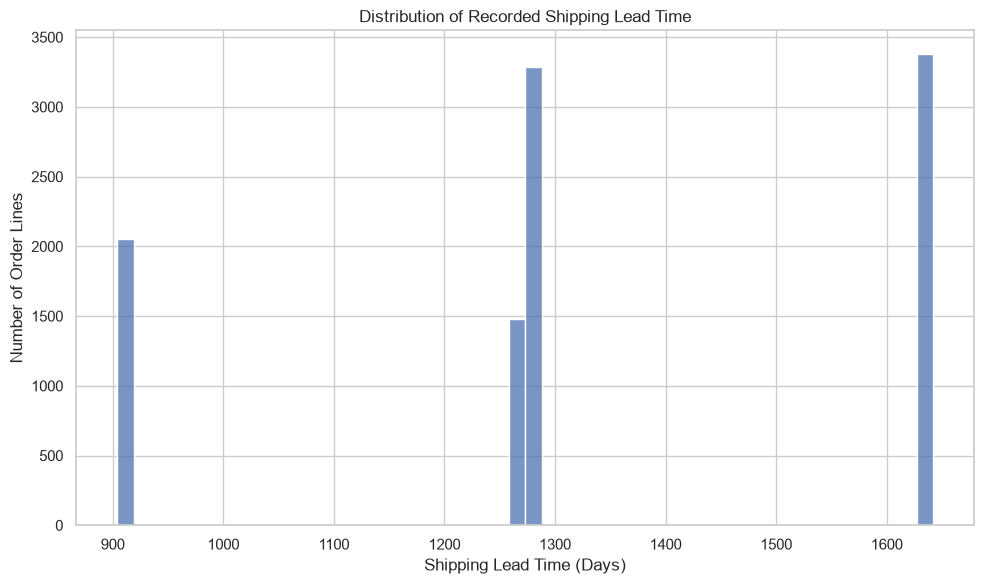

In [33]:
# 2.5.2 Plot the distribution
# ============================================
# STEP 2.5A: LEAD-TIME DISTRIBUTION
# ============================================

valid_lead_time = df["Shipping Lead Time Days"].dropna()

plt.figure(figsize=(10, 6))

sns.histplot(
    valid_lead_time,
    bins=50,
    kde=False
)

plt.title("Distribution of Recorded Shipping Lead Time")
plt.xlabel("Shipping Lead Time (Days)")
plt.ylabel("Number of Order Lines")

plt.tight_layout()
plt.show()

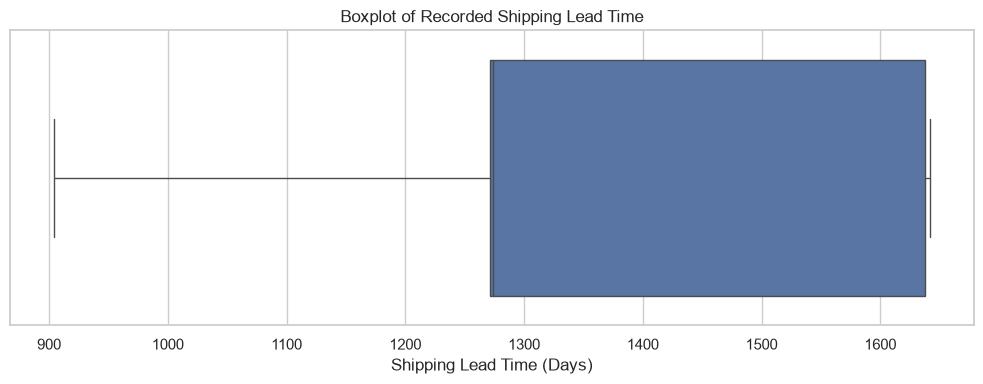

In [34]:
#2.5.3 Create a boxplot
# ============================================
# STEP 2.5B: LEAD-TIME BOXPLOT
# ============================================

plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df["Shipping Lead Time Days"]
)

plt.title("Boxplot of Recorded Shipping Lead Time")
plt.xlabel("Shipping Lead Time (Days)")

plt.tight_layout()
plt.show()



In [35]:
# ============================================
# STEP 2.6: LEAD TIME BY REGION
# ============================================

lead_time_by_region = (
    df.groupby("Region")
      .agg(
          Order_Lines=("Row ID", "count"),
          Average_Lead_Time=("Shipping Lead Time Days", "mean"),
          Median_Lead_Time=("Shipping Lead Time Days", "median"),
          P90_Lead_Time=(
              "Shipping Lead Time Days",
              lambda x: x.quantile(0.90)
          ),
          Average_Sales=("Sales", "mean"),
          Average_Gross_Profit=("Gross Profit", "mean")
      )
      .sort_values("Median_Lead_Time", ascending=True)
)

display(lead_time_by_region)

,Order_Lines,Average_Lead_Time,Median_Lead_Time,P90_Lead_Time,Average_Sales,Average_Gross_Profit
Region,,,,,,
Atlantic,2986,1322.745144,1274.0,1640.0,13.796798,9.033389
Gulf,1620,1311.374691,1274.0,1640.0,13.732877,9.074488
Interior,2335,1323.091221,1274.0,1640.0,13.720600,9.114557
Pacific,3253,1322.194897,1274.0,1640.0,14.233486,9.371638


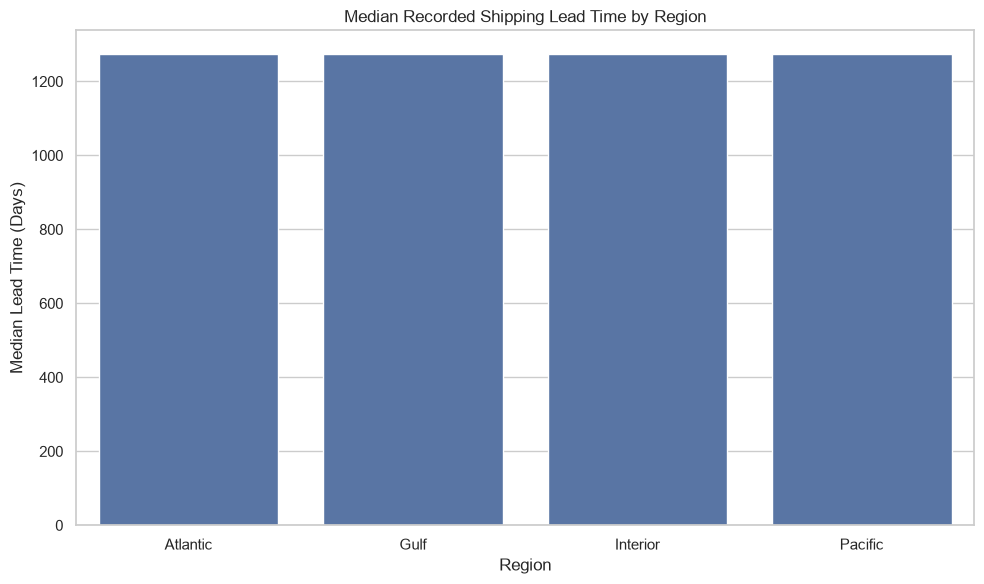

In [36]:
# ============================================
# STEP 2.6A: REGION VS MEDIAN LEAD TIME
# ============================================

plot_data = lead_time_by_region.reset_index()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_data,
    x="Region",
    y="Median_Lead_Time"
)

plt.title("Median Recorded Shipping Lead Time by Region")
plt.xlabel("Region")
plt.ylabel("Median Lead Time (Days)")

plt.tight_layout()
plt.show()

#Business interpretation

#This analysis identifies regions with higher or lower recorded lead times.

#However, regional differences do not prove that the destination region causes longer shipping times. Product mix, shipping mode, order dates, and other factors may also explain the differences.




,Order_Lines,Average_Lead_Time,Median_Lead_Time,P90_Lead_Time
Ship Mode,,,,
Same Day,547,1333.442413,1269.0,1635.0
First Class,1548,1338.275840,1272.0,1638.0
Second Class,1979,1323.845376,1273.0,1639.0
Standard Class,6120,1314.334641,1274.0,1640.0


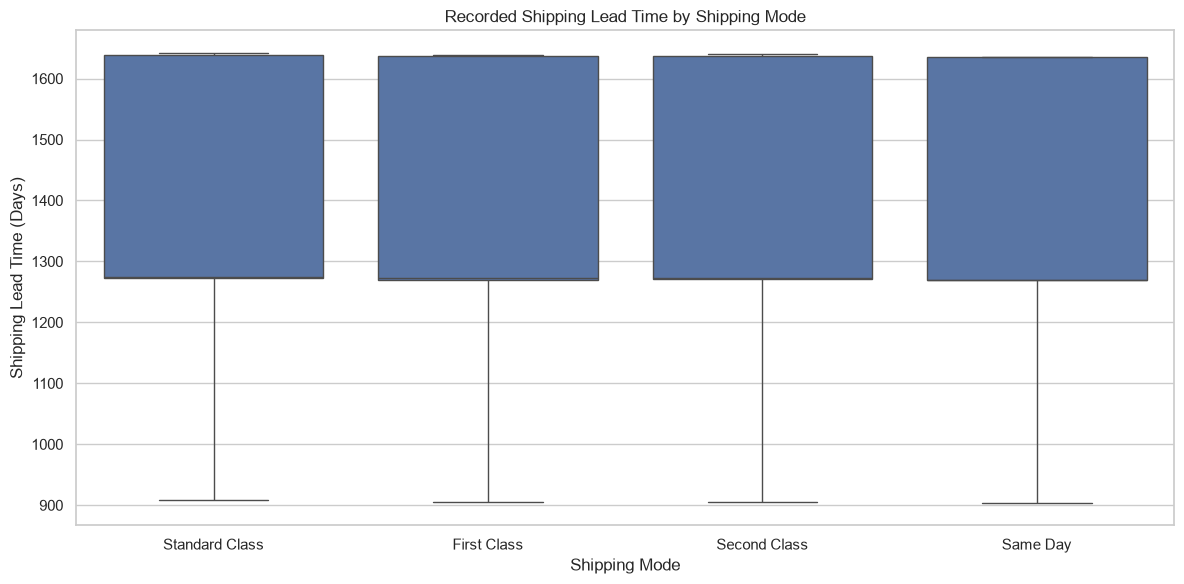

In [39]:
# ============================================
# STEP 2.7: LEAD TIME BY SHIPPING MODE
# ============================================

lead_time_by_mode = (
    df.groupby("Ship Mode")
      .agg(
          Order_Lines=("Row ID", "count"),
          Average_Lead_Time=("Shipping Lead Time Days", "mean"),
          Median_Lead_Time=("Shipping Lead Time Days", "median"),
          P90_Lead_Time=(
              "Shipping Lead Time Days",
              lambda x: x.quantile(0.90)
          )
      )
      .sort_values("Median_Lead_Time")
)
display(lead_time_by_mode)
# ============================================
# STEP 2.7A: SHIPPING MODE BOXPLOT
# ============================================

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="Ship Mode",
    y="Shipping Lead Time Days"
)

plt.title("Recorded Shipping Lead Time by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Shipping Lead Time (Days)")

plt.tight_layout()
plt.show()


,Product ID,Product Name,Order_Lines,Unique_Orders,Total_Units,Total_Sales,Total_Cost,Total_Gross_Profit,Gross Margin (%)
3,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,2064,1704,7743,27874.80,8517.30,19357.50,69.444444
4,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,2015,1677,7596,28485.00,9874.80,18610.20,65.333333
1,CHO-MIL-31000,Wonka Bar - Milk Chocolate,2137,1768,8267,26867.75,9424.38,17443.37,64.923077
2,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,1810,1529,6755,23574.95,6755.00,16819.95,71.346705
0,CHO-FUD-51000,Wonka Bar - Fudge Mallows,1818,1527,6914,24890.40,8296.80,16593.60,66.666667
8,OTH-LIC-15000,Lickable Wallpaper,94,92,393,7860.00,3930.00,3930.00,50.000000
6,OTH-GUM-21000,Wonka Gum,120,118,478,597.50,286.80,310.70,52.000000
9,SUG-EVE-47000,Everlasting Gobstopper,3,3,13,130.00,26.00,104.00,80.000000
7,OTH-KAZ-38000,Kazookles,96,94,371,1205.75,1113.00,92.75,7.692308
11,SUG-HAI-55000,Hair Toffee,4,4,17,76.50,17.00,59.50,77.777778


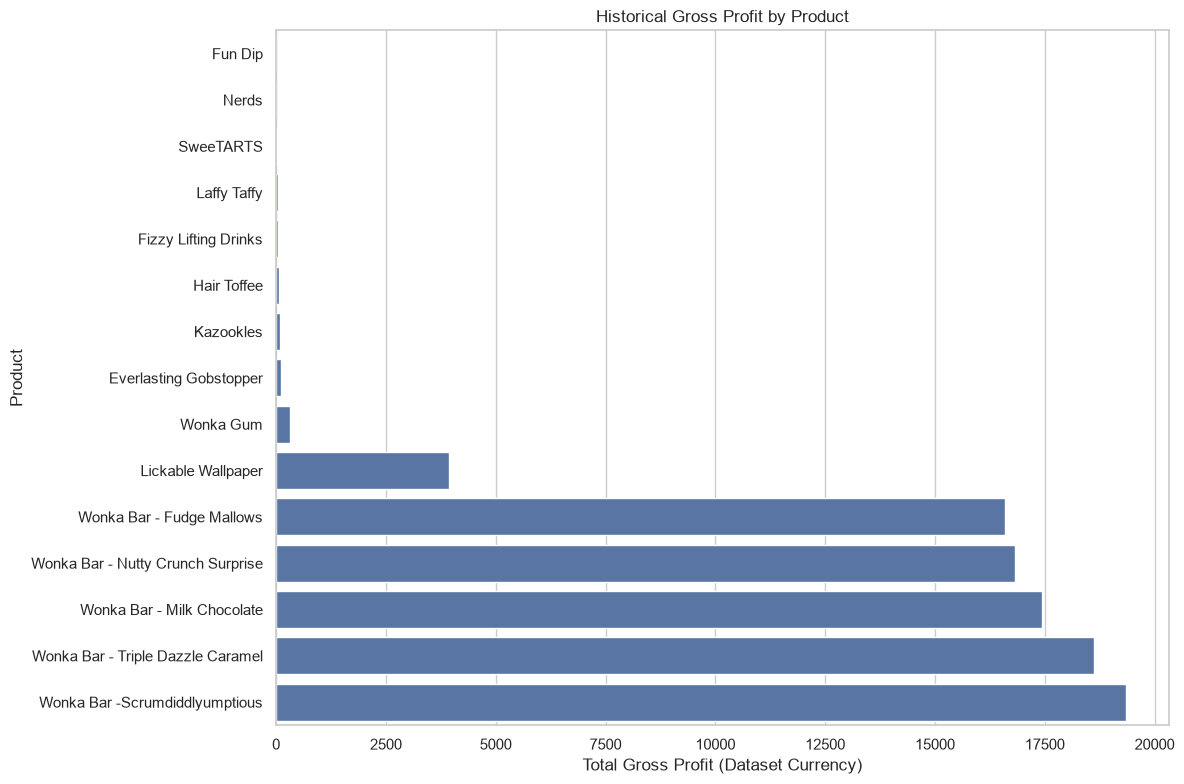

In [40]:
# ============================================
# STEP 2.8: PRODUCT FINANCIAL PERFORMANCE
# ============================================

product_performance = (
    df.groupby(["Product ID", "Product Name"])
      .agg(
          Order_Lines=("Row ID", "count"),
          Unique_Orders=("Order ID", "nunique"),
          Total_Units=("Units", "sum"),
          Total_Sales=("Sales", "sum"),
          Total_Cost=("Cost", "sum"),
          Total_Gross_Profit=("Gross Profit", "sum")
      )
      .reset_index()
)

# Calculate historical gross margin where sales are positive
product_performance["Gross Margin (%)"] = np.where(
    product_performance["Total_Sales"] > 0,
    (
        product_performance["Total_Gross_Profit"]
        / product_performance["Total_Sales"]
    ) * 100,
    np.nan
)

product_performance = product_performance.sort_values(
    "Total_Gross_Profit",
    ascending=False
)

display(product_performance)


#What is gross margin?
#$$ \text{Gross Margin (\%)} = \frac{\text{Gross Profit}}{\text{Sales}} \times 100 $$
#This calculation assumes that the supplied gross profit and sales fields are comparable and that gross profit is defined consistently.


# ============================================
# STEP 2.8A: GROSS PROFIT BY PRODUCT
# ============================================

profit_plot = product_performance.sort_values(
    "Total_Gross_Profit",
    ascending=True
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=profit_plot,
    x="Total_Gross_Profit",
    y="Product Name"
)

plt.title("Historical Gross Profit by Product")
plt.xlabel("Total Gross Profit (Dataset Currency)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

,Order_Month,Order_Lines,Unique_Orders,Total_Sales,Total_Gross_Profit
0,2024-01-01,148,115,2093.90,1366.14
1,2024-02-01,110,97,1379.87,908.59
2,2024-03-01,300,255,4138.90,2671.16
3,2024-04-01,295,239,3988.22,2612.81
4,2024-05-01,282,245,3951.52,2615.44
5,2024-06-01,274,227,3518.76,2330.72
6,2024-07-01,283,223,3865.38,2565.26
7,2024-08-01,320,260,4477.65,2945.87
8,2024-09-01,568,479,7912.10,5206.70
9,2024-10-01,335,275,4815.98,3119.46


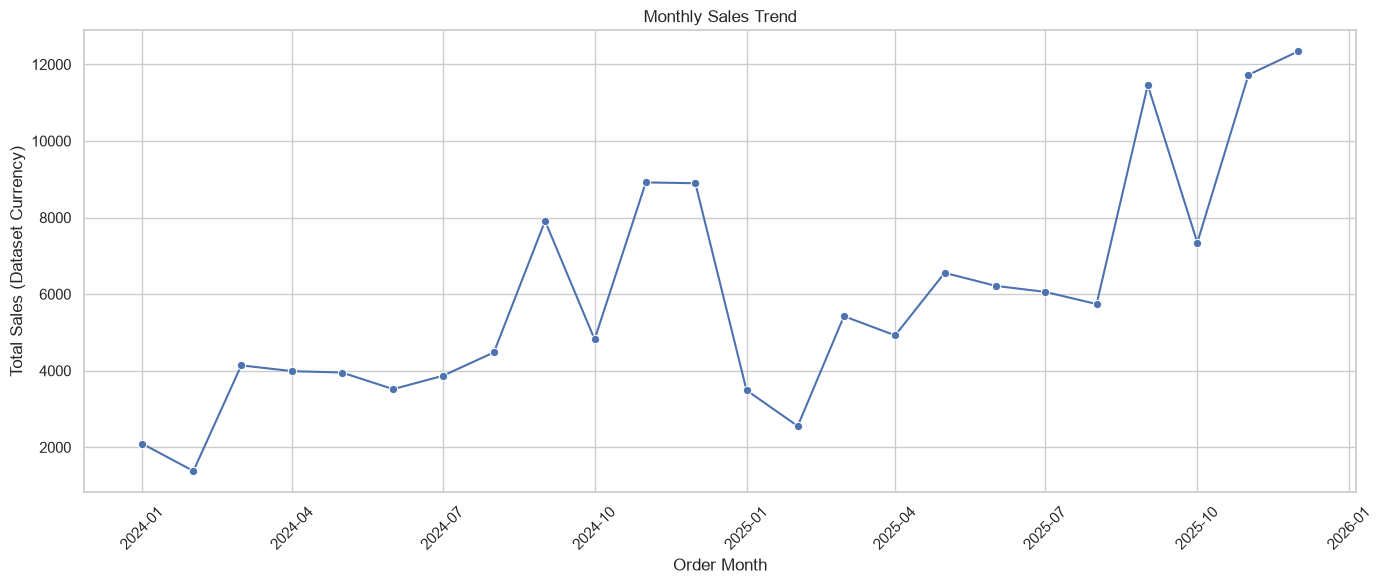

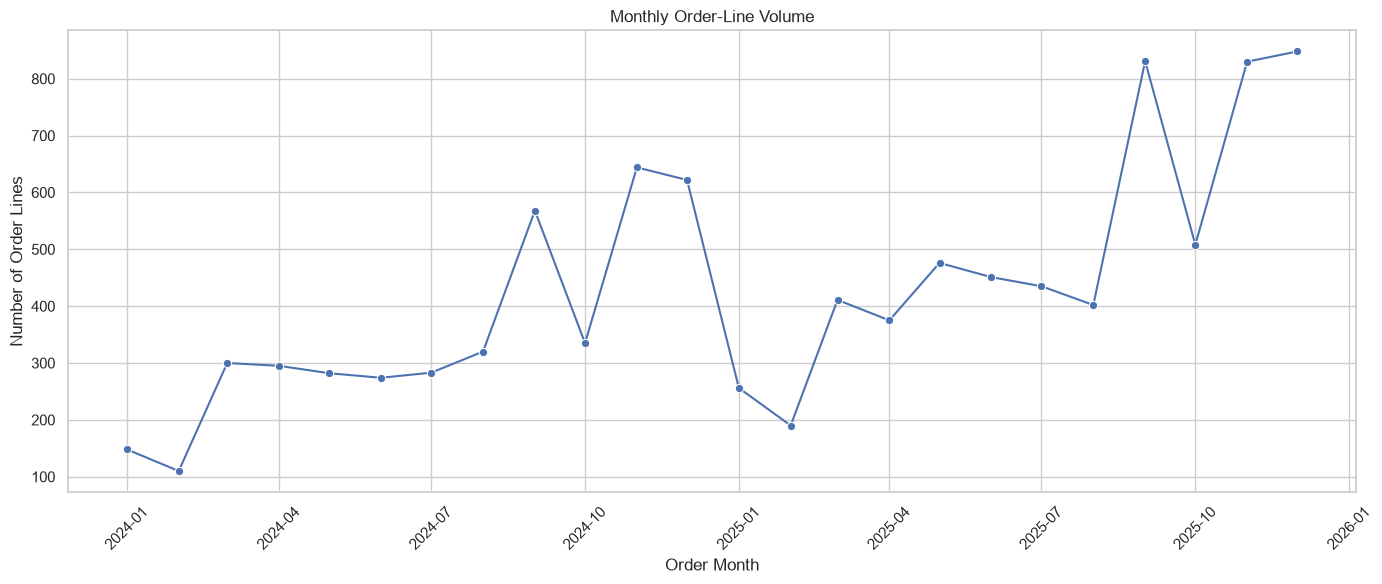

In [42]:
# ============================================
# STEP 2.10: MONTHLY ORDER TRENDS
# ============================================

# Ensure 'Order Date' is properly recognized as datetime
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

if df["Order Date"].isna().any():
    print("Warning: Some Order Date values are invalid. The monthly analysis will exclude those records.")

monthly_orders = (
    df.dropna(subset=["Order Date"])
    .assign(
        Order_Month=lambda x: x["Order Date"].dt.to_period("M").dt.to_timestamp()
    )
    .groupby("Order_Month")
    .agg(
        Order_Lines=("Row ID", "count"),
        Unique_Orders=("Order ID", "nunique"),
        Total_Sales=("Sales", "sum"),
        Total_Gross_Profit=("Gross Profit", "sum")
    )
    .reset_index()
)

display(monthly_orders.head(12))


# ============================================
# STEP 2.10A: MONTHLY SALES TREND
# ============================================

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_orders,
    x="Order_Month",
    y="Total_Sales",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Order Month")
plt.ylabel("Total Sales (Dataset Currency)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



# ============================================
# STEP 2.10B: MONTHLY ORDER-LINE TREND
# ============================================

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_orders,
    x="Order_Month",
    y="Order_Lines",
    marker="o"
)

plt.title("Monthly Order-Line Volume")
plt.xlabel("Order Month")
plt.ylabel("Number of Order Lines")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# These charts describe recorded historical order activity.



,Sales,Units,Gross Profit,Cost,Shipping Lead Time Days
Sales,1.000000,0.729347,0.976404,0.958986,-0.005438
Units,0.729347,1.000000,0.815820,0.563344,-0.006702
Gross Profit,0.976404,0.815820,1.000000,0.875144,-0.003305
Cost,0.958986,0.563344,0.875144,1.000000,-0.007846
Shipping Lead Time Days,-0.005438,-0.006702,-0.003305,-0.007846,1.000000


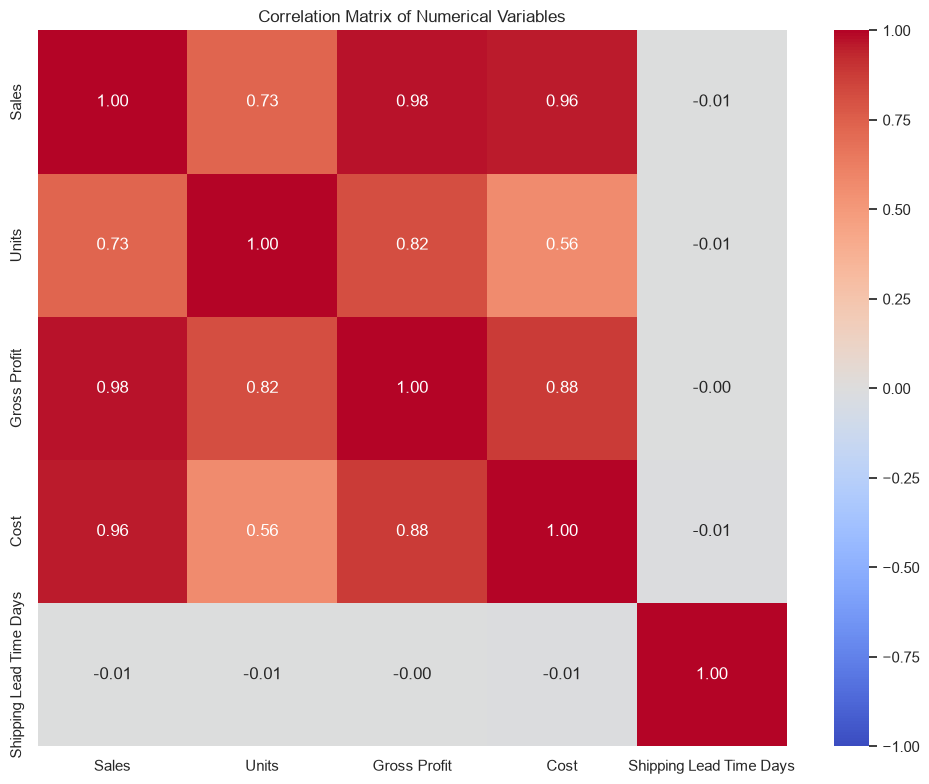

In [44]:

# ============================================
# STEP 2.11: CORRELATION MATRIX
# ============================================

correlation_columns = [
    "Sales",
    "Units",
    "Gross Profit",
    "Cost",
    "Shipping Lead Time Days"
]

correlation_matrix = df[
    correlation_columns
].corr(method="pearson")

display(correlation_matrix)

# ============================================
# STEP 2.11A: CORRELATION HEATMAP
# ============================================

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Numerical Variables")

plt.tight_layout()
plt.show()


#Interpretation

#Correlation coefficients range from −1 to +1.

#A positive coefficient indicates that two variables tend to increase together.
#A negative coefficient indicates that one tends to decrease as the other increases.
#A coefficient near zero indicates little linear association.

#Correlation does not prove causation.

In [46]:
# ============================================
# STEP 2.12: IQR OUTLIER INVESTIGATION
# ============================================

outlier_columns = [
    "Sales",
    "Units",
    "Gross Profit",
    "Cost",
    "Shipping Lead Time Days"
]

outlier_results = []

for column in outlier_columns:

    series = df[column].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (df[column] < lower_bound)
        | (df[column] > upper_bound)
    )

    outlier_count = int(outlier_mask.sum())

    outlier_percentage = (
        outlier_count / len(df) * 100
        if len(df) > 0
        else np.nan
    )

    outlier_results.append({
        "Column": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count,
        "Outlier Percentage": outlier_percentage
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)
          

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Sales,7.2,18.00,10.80,-9.000,34.200,245,2.403375
1,Units,2.0,5.00,3.00,-2.500,9.500,175,1.716696
2,Gross Profit,4.9,12.25,7.35,-6.125,23.275,217,2.128703
3,Cost,2.4,5.70,3.30,-2.550,10.650,397,3.894448
4,Shipping Lead Time Days,1271.0,1638.00,367.00,720.500,2188.500,0,0.000000


In [51]:
# ============================================
# STEP 2.13: SAVE EDA TABLES
# ============================================
from pathlib import Path

# Target the data directory directly
output_folder = Path("nassau-candy-factory-optimization/data")
output_folder.mkdir(parents=True, exist_ok=True)

orders_by_region.to_csv(output_folder / "orders_by_region.csv")
shipping_mode_summary.to_csv(output_folder / "shipping_mode_summary.csv")
lead_time_by_region.to_csv(output_folder / "lead_time_by_region.csv")
lead_time_by_mode.to_csv(output_folder / "lead_time_by_shipping_mode.csv")
product_performance.to_csv(output_folder / "product_financial_performance.csv", index=False)
monthly_orders.to_csv(output_folder / "monthly_order_trends.csv", index=False)
outlier_summary.to_csv(output_folder / "outlier_investigation.csv", index=False)

print("EDA tables saved successfully inside:", output_folder.resolve())

EDA tables saved successfully inside: C:\Users\Administrator\nassau-candy-factory-optimization\data
